In [1]:
from src.config import corpus_config, experiment_config
from src.utils import MetricsJson, metrics_dir, phase_1_metrics_filename
from nb_utils import plot_figure
from src.visualizations import grassmann_distance_curve, singular_values_curve
from pathlib import Path
import json

In [2]:
def get_metrics(metrics_dir: Path=metrics_dir, metrics_filename: str=phase_1_metrics_filename) -> MetricsJson:
    metrics_filepath = metrics_dir / f'{metrics_filename}.json'
    with open(metrics_filepath, 'r') as metrics_file:
        metrics = json.load(metrics_file)
    return metrics


def get_singular_values(metrics: MetricsJson, corpus_name: str, layer_idx: int | str, tensor_type: str) -> list[float]:
    layer_idx = str(layer_idx)
    singular_values = metrics[layer_idx][tensor_type]['singular_values'][corpus_name]
    return singular_values


def get_grassmann_distances(metrics: MetricsJson, tensor_type: str) -> dict[str, list[float]]:
    layer_indices = sorted([int(key) for key in metrics.keys() if key != 'metadata'])

    distances_dict = {}
    for layer_idx in layer_indices:
        distances = metrics[str(layer_idx)][tensor_type]['grassmann_distances']

        for comparison, distance in distances.items():
            if comparison not in distances_dict:
                distances_dict[comparison] = []
            distances_dict[comparison].append(distance)

    return distances_dict


def get_baseline_distance(metrics: MetricsJson, tensor_type: str) -> float:
    baseline_distance = metrics['metadata']['baseline'][tensor_type]
    return baseline_distance


if __name__ == '__main__':
    metrics = get_metrics()

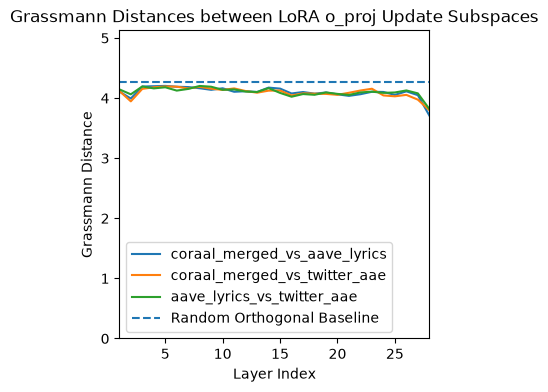

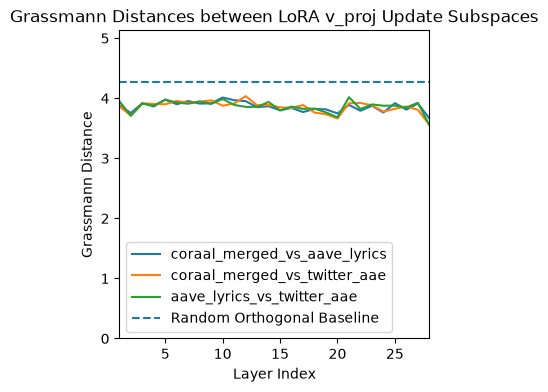

In [3]:
for tensor_type in experiment_config.target_weight_matrices:
    baseline_distance = get_baseline_distance(metrics, tensor_type)
    distances_dict = get_grassmann_distances(metrics, tensor_type)
    fig = grassmann_distance_curve(tensor_type, distances_dict, baseline_distance)

plot_figure(fig)

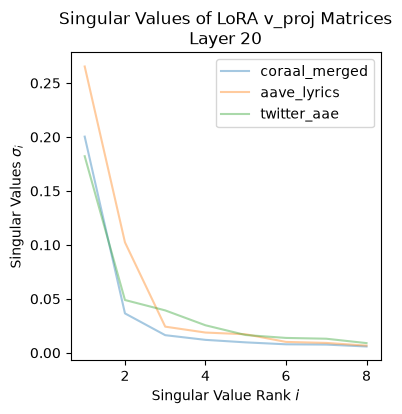

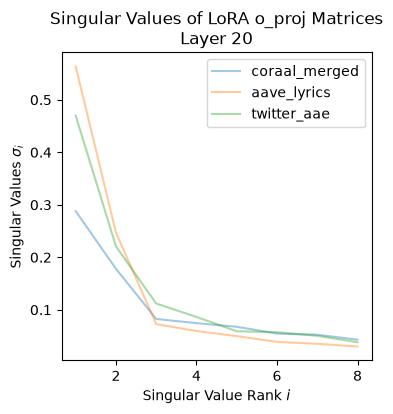

In [ ]:
peak_activation_layer_idx = 20

for tensor_type in experiment_config.target_weight_matrices:
    singular_values_dict = {
        corpus_name: get_singular_values(
            metrics,
            corpus_name,
            peak_activation_layer_idx,
            tensor_type,
        )
        for corpus_name in corpus_config
    }

    fig = singular_values_curve(
        peak_activation_layer_idx,
        tensor_type,
        singular_values_dict,
    )

    plot_figure(fig)